In [1]:
PATH = "Assignment2 Data/"

In [2]:
!pip install scikit-image

Defaulting to user installation because normal site-packages is not writeable


## 1. Image Classification using HoG (10 points)

In [3]:
TRAIN_DIR = PATH+"Q1/training"
TEST_DIR = PATH+"Q1/test"

In [4]:
from skimage.io import imread
from skimage.transform import resize
from skimage.feature import hog
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
import cv2
import os 
import numpy as np

### 1.1 Build a classifier with training images

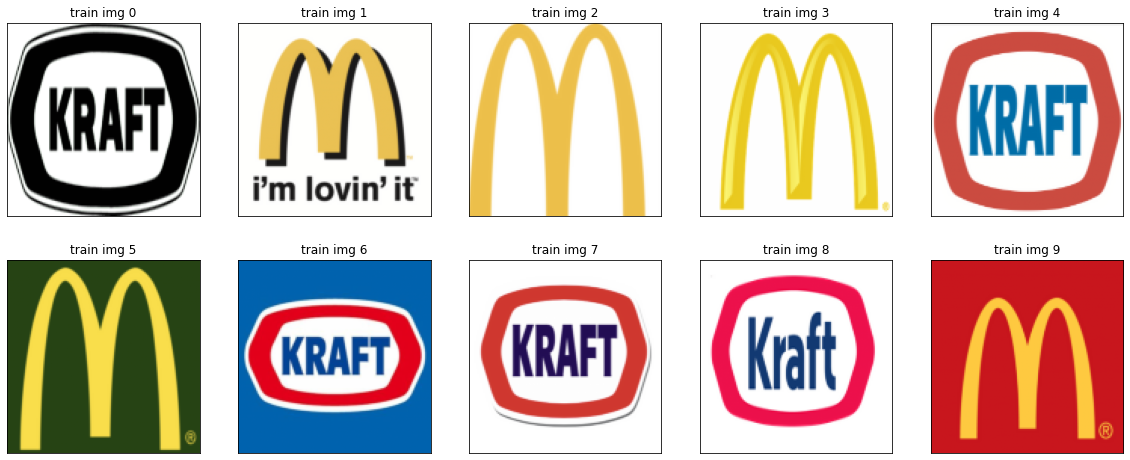

In [5]:
# 1. Resize the training images to 128 x 128. 
# read, resize, and show training set images 

IMG_SIZE = (128, 128) 
TRAIN_IMAGES = [] 
TEST_IMAGES = []
fig, ax = plt.subplots(2, 5, figsize=(20, 8))


# read images in the train and test directory 
counter = 0
for image_f in os.listdir(TRAIN_DIR):
    img = imread(os.path.join(TRAIN_DIR, image_f)) # resize train images
    img = resize(img, IMG_SIZE)
    TRAIN_IMAGES.append(img)
    ax[counter//5][counter%5].imshow(img)
    ax[counter//5][counter%5].title.set_text(f"train img {counter}")
    ax[counter//5][counter%5].tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)
    counter += 1

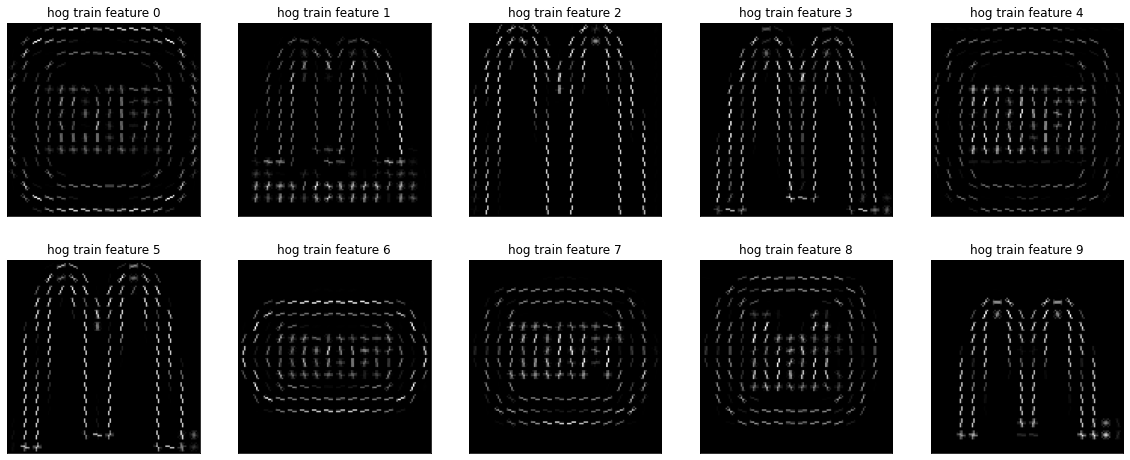

In [6]:
# constants 
PIXELS_CELL = (8, 8)
CELLS_BLOCK = (4, 4)
NUM_ORIENTATION_BINS = 8

# 2. Compute HoG features of size (32, 32, 8) for all training images.
# 3. Apply blocknorm in 4x4 cell neighborhoods.
hog_features = [hog(img, orientations=NUM_ORIENTATION_BINS, pixels_per_cell=PIXELS_CELL,cells_per_block=CELLS_BLOCK, visualize=True, channel_axis=-1) for img in TRAIN_IMAGES]


counter = 0
fig, ax = plt.subplots(2, 5, figsize=(20, 8))
for features in hog_features:
    ax[counter//5][counter%5].imshow(features[1], cmap="gray")
    ax[counter//5][counter%5].title.set_text(f"hog train feature {counter}")
    ax[counter//5][counter%5].tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)
    counter += 1
    

features = np.array([features[1].flatten() for features in hog_features])

In [7]:
nsamples, nx, ny = features.shape
features = features.reshape((nsamples,nx*ny))

# nsamples, nx, ny = features_test.shape
# features_test = features_test.reshape((nsamples,nx*ny))

ValueError: not enough values to unpack (expected 3, got 2)

In [ ]:
# manually label train images 
targets = ["Kraft", "McDonald’s", "McDonald’s", "McDonald’s", "Kraft", "McDonald’s", "Kraft", "Kraft", "Kraft", "McDonald’s"]

# 4. Fit a nearest neighbor classifier with three neighbors. Use KNeighborsClassifier from sklearn library.
N_NEIGHBORS = 3
clf = KNeighborsClassifier(n_neighbors = N_NEIGHBORS)
clf.fit(features, targets)

### 1.2 Classify test images

In [ ]:
#1. Compute HoG features for all test images.

fig, ax = plt.subplots(1, 4, figsize=(15, 5))
counter = 0
for image_f in os.listdir(TEST_DIR):
    img = imread(os.path.join(TEST_DIR, image_f)) # resize train images
    img = resize(img, IMG_SIZE)
    TEST_IMAGES.append(img)
    ax[counter%4].imshow(img)
    ax[counter%4].title.set_text(f"test img {counter}")
    ax[counter%4].tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)
    counter += 1
    
#2. Display the HoG features for all test images.
hog_test_features = [hog(img, orientations=NUM_ORIENTATION_BINS, pixels_per_cell=PIXELS_CELL,cells_per_block=CELLS_BLOCK, visualize=True, channel_axis=-1) for img in TEST_IMAGES]
counter = 0
fig, ax = plt.subplots(1, 4, figsize=(20, 8))
for features in hog_test_features:
    ax[counter%4].imshow(features[1], cmap="gray")
    ax[counter%4].title.set_text(f"hog test feature {counter}")
    ax[counter%4].tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)
    counter += 1
    
features_test = np.array([features[1].flatten() for features in hog_test_features])

# 3. Classify the test images using the classifier you built above.
# predict test set labels 
print("Predicted Label:", clf.predict(features_test))

4. Does the classifier work on all test images? Discuss which properties of HoG features help
to classify the images. Which computer vision methods will you use for classifying logos
under rotation.